# Fresnel lenses: from a thick lens to a solar concentrator

In 1822 Augustin Fresnel proposed to build lighthouse lenses not from one
huge block of glass but from rings: a lens refracts only at its surfaces, so
the glass that merely holds the surface at its height can go. Cut the sag
into annular zones and lower every zone onto a common plane, and what
remains is a thin plate with a sawtooth relief of **facets** (the refracting
parts, with the slopes of the original surface) and **risers** (the steps
between the zones). Moulded in PMMA, Fresnel lenses now concentrate sunlight
onto photovoltaic cells, condense the light of overhead projectors and
spotlights, and serve as field lenses in cameras and VR headsets.

This notebook follows one real-world lens through `pyoptics.fresnel`: the
primary of a **concentrator photovoltaic (CPV) module**, a 100 mm PMMA
Fresnel lens of focal length 150 mm (F/1.5) that focuses the sun onto a
5 mm × 5 mm multi-junction cell, about 300 suns geometric concentration
(Leutz and Suzuki 2001).

1. **Thick lens → Fresnel lens.** The aberration free thick lens, its
   collapse into zones, and how much material goes.
2. **Same slopes, different lens.** The usual idealization (the facets on a
   plane, with the slopes of the parent) and why the parent of a good
   Fresnel lens is *not* the good thick lens; an exact facet design and the
   way back to an equivalent asphere.
3. **Real facets.** Ray tracing through the sawtooth: the groove depth,
   curved vs. flat (conical) facets and the pitch.
4. **Where the light goes.** Draft losses, shadowing by the risers and
   Fresnel reflection, with the grooves facing the cell or the sun.
5. **The sun in colour.** The solar disk and the dispersion of PMMA on the
   cell, concentration and the acceptance angle of the module.
6. **Waves: Fresnel lens vs. kinoform.** Deep grooves add the zones
   incoherently; one wave deep grooves make a diffractive lens with the
   opposite, much stronger colour.

**References:** A. Fresnel, *Mémoire sur un nouveau système d'éclairage des
phares* (1822); R. Leutz and A. Suzuki, *Nonimaging Fresnel Lenses: Design
and Performance of Solar Concentrators*, Springer (2001); W. T. Welford,
*Aberrations of Optical Systems*, Adam Hilger (1986); D. A. Buralli, G. M.
Morris and J. R. Rogers, Appl. Opt. 28, 976 (1989); D. C. O'Shea et al.,
*Diffractive Optics*, SPIE Press (2004); N. Sultanova, S. Kasarova and
I. Nikolov, Acta Phys. Pol. A 116, 585 (2009) (PMMA index); A. Davis and
F. Kühnlenz, Optik & Photonik 2(4), 52 (2007).

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colormaps
from matplotlib.colors import ListedColormap
from scipy.special import j0

from pyoptics.raytrace import Surface, System, Rays
from pyoptics import fresnel as fr
from pyoptics.fresnel import FresnelSurface, FACET, RISER, SHADOWED

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
t = np.linspace(0, 1, 256)[:, None]
LIGHT = ListedColormap(1 - (1 - colormaps["magma_r"](t[:, 0])[:, :3])*np.clip(t/0.15, 0, 1),
                       name="light")         # magma_r, fading to white at zero
t_start = time.time()

WL = 550e-6                     # design wavelength (mm)
N = float(fr.pmma(550.0))       # PMMA at 550 nm
F, A, T = 150.0, 50.0, 3.0      # focal length, semi diameter, plate thickness (mm)
PITCH, DRAFT = 0.5, np.radians(2.0)
print("PMMA: n(550 nm) = {:.4f}, n_d = {:.4f}, n(400) - n(1100) = {:.4f}".format(
    N, fr.pmma(587.56), fr.pmma(400) - fr.pmma(1100)))

PMMA: n(550 nm) = 1.4926, n_d = 1.4906, n(400) - n(1100) = 0.0264


## 1. From the thick lens to the Fresnel lens

The sun comes in through the flat side; the curved side faces the cell. A
collimated beam inside glass is focused without aberrations into air by a
**hyperboloid** of eccentricity $n$, conic constant $K = -n^2$, with the
vertex radius $R = -(n - 1)f$ (a Cartesian oval for an object at infinity).
At F/1.5 this lens is 18 mm thick in the middle.

`FresnelSurface.from_surface()` collapses its exit surface into zones of
constant pitch: facet $k$ is $f_k(r) = z_p(r) - z_p(r_k)$ on
$r_k \le r < r_{k+1}$, it starts on the base plane and ends with the step
$h_k$, where a riser returns to the plane. A draft angle of 2° tilts the
risers so the part can leave the mould; a riser then covers the start of the
next facet over $|h_k|\tan\delta$.

In [2]:
R_hyp, K_hyp = -(N - 1)*F, -N**2
hyper = Surface(R_hyp, conic=K_hyp)
sag_rim = -hyper.sag(A**2)
thick = System([Surface(np.inf, T + sag_rim, material=fr.pmma, semi_diameter=A, label="flat"),
                Surface(R_hyp, F, n_after=1.0, conic=K_hyp, semi_diameter=A, label="hyperboloid")],
               0, WL)
print("thick lens: centre thickness {:.1f} mm, BFL {:.2f} mm, RMS spot {:.1e} mm".format(
    T + sag_rim, thick.paraxial().bfl, thick.spot_diagram(0.0, N=41).rms))

fz = FresnelSurface(R_hyp, F, conic=K_hyp, n_after=1.0, semi_diameter=A, pitch=PITCH,
                    draft=DRAFT)
g = fz._geometry()
print("Fresnel version: {} zones of {} mm, groove depth {:.3f} mm (centre) to {:.3f} mm (rim)"
      .format(fz.n_zones, PITCH, abs(g["h"][1]), abs(g["h"][-1])))

# volume of PMMA (density 1.18 g/cm^3) between the flat side and the surface:
r = (np.arange(20000) + 0.5)*A/20000
vol = lambda thickness: np.sum(2*np.pi*r*thickness)*(A/20000)/1e3     # cm^3
v_thick = vol(T + sag_rim + hyper.sag(r**2))
v_fres = vol(T + fz.profile(r))
print("PMMA: thick lens {:.0f} g, Fresnel lens {:.0f} g ({:.0f} % of the material)".format(
    1.18*v_thick, 1.18*v_fres, 100*v_fres/v_thick))

thick lens: centre thickness 18.0 mm, BFL 150.00 mm, RMS spot 1.1e-14 mm
Fresnel version: 100 zones of 0.5 mm, groove depth 0.005 mm (centre) to 0.270 mm (rim)
PMMA: thick lens 95 g, Fresnel lens 27 g (28 % of the material)


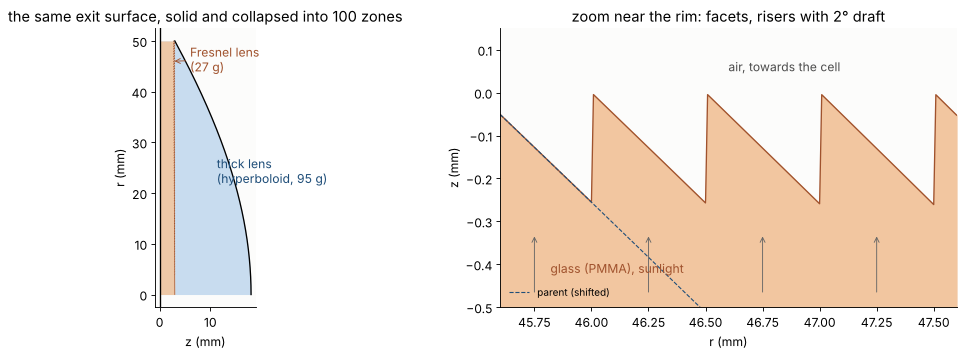

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
yy = np.linspace(0, A, 400)
ax.fill_betweenx(yy, 0, T + sag_rim + hyper.sag(yy**2), color="#c8dcef", lw=0)
ax.plot(T + sag_rim + hyper.sag(yy**2), yy, color="k", lw=1.2)
y, z = fz.section(A, n_per_zone=6)
y, z = y[y >= 0], z[y >= 0]
ax.fill_betweenx(y, 0, T + z, color="#f2c6a0", lw=0, alpha=0.9)
ax.plot(T + z, y, color="#a0522d", lw=0.6)
ax.axvline(0, color="k", lw=1.2)
ax.text(T + sag_rim*0.55, 22, "thick lens\n(hyperboloid, {:.0f} g)".format(1.18*v_thick), color="#1f4e79")
ax.annotate("Fresnel lens\n({:.0f} g)".format(1.18*v_fres), (2.5, 46), (6, 44), color="#a0522d",
            arrowprops=dict(arrowstyle="->", color="#a0522d", lw=0.8))
ax.set_xlabel("z (mm)"), ax.set_ylabel("r (mm)")
ax.set_title("the same exit surface, solid and collapsed into {} zones".format(fz.n_zones))
ax.set_aspect("equal")
ax = axes[1]
rr = np.linspace(45.6, 47.6, 3000)
zz = fz.profile(rr)
ax.fill_between(rr, -0.5, zz, color="#f2c6a0")
ax.plot(rr, zz, color="#a0522d", lw=1.2)
ax.plot(rr, hyper.sag(rr**2) - hyper.sag(np.array([45.5**2]))[0], color="#1f4e79", lw=1,
        ls="--", label="parent (shifted)")
for x in np.arange(45.75, 47.6, 0.5):          # the sunlight, inside the glass
    ax.annotate("", (x, -0.33), (x, -0.47), arrowprops=dict(arrowstyle="->", color="0.4", lw=0.8))
ax.text(45.82, -0.42, "glass (PMMA), sunlight", color="#a0522d")
ax.text(46.6, 0.05, "air, towards the cell", color="0.3")
ax.set_xlim(rr[0], rr[-1]), ax.set_ylim(-0.5, 0.15)
ax.set_xlabel("r (mm)"), ax.set_ylabel("z (mm)")
ax.set_title("zoom near the rim: facets, risers with 2° draft")
ax.legend(loc="lower left", fontsize=9, frameon=False)
plt.tight_layout()
plt.show()

The Fresnel lens needs 28 % of the material, and almost all of that is the
3 mm plate that carries the relief; the grooves are 5 µm deep at the centre
and 0.27 mm at the rim. In the zoom the light travels upwards: out of the
glass, through the facets, towards the cell 150 mm above.

## 2. Same slopes, different lens

Ray tracing programs model a Fresnel surface by the plane it sits on: the
rays meet the base plane and are refracted with the normal that the parent
surface has *at the same radius* (`model="ideal"`, the "Fresnel" surface of
Zemax OpticStudio). This is the limit of an infinitely fine relief. Is the
Fresnel version of the perfect thick lens perfect, too?

In [4]:
def concentrator(parent, model="facets", **kwargs):
    # the flat entrance face (also the stop) and the Fresnel surface, image at the focus
    kwargs.setdefault("pitch", PITCH)
    fs = FresnelSurface.from_surface(parent, thickness=F, n_after=1.0, semi_diameter=A,
                                     model=model, **kwargs)
    return System([Surface(np.inf, T, material=fr.pmma, semi_diameter=A, label="flat"), fs], 0, WL)


ideal_hyp = concentrator(hyper, model="ideal")
print("ideal Fresnel surface with the hyperboloid as parent: RMS spot {:.2f} mm".format(
    ideal_hyp.spot_diagram(0.0, N=41).rms))

# the exact facets: normal parallel to n d - n' d' (d along the axis, d' towards the focus)
r_d = np.linspace(0, A, 400)
slope = fr.focusing_slopes(r_d, F, N, 1.0)
designed, rms_slope = fr.surface_from_slopes(r_d, slope, n_aspheric=6)
print("designed parent: R = {:.3f} mm, A4..A14 = {}, slope residual {:.1e}".format(
    designed.R, np.array2string(np.array(designed.aspheric), precision=3), rms_slope))
ideal_des = concentrator(designed, model="ideal")
thick_des = System([Surface(np.inf, T + 15, material=fr.pmma, semi_diameter=A),
                    Surface(designed.R, F, n_after=1.0, aspheric=designed.aspheric,
                            semi_diameter=A)], 0, WL)
for name, s in [("ideal Fresnel, designed parent", ideal_des),
                ("thick lens with the designed surface", thick_des)]:
    print("{:38s} RMS spot {:.2e} mm".format(name, s.spot_diagram(0.0, N=41).rms))

ideal Fresnel surface with the hyperboloid as parent: RMS spot 2.37 mm
designed parent: R = -73.889 mm, A4..A14 = [ 5.375e-07  1.715e-11  3.007e-15  1.078e-18 -2.135e-22  5.539e-26], slope residual 2.1e-07
ideal Fresnel, designed parent         RMS spot 2.71e-05 mm
thick lens with the designed surface   RMS spot 2.65e+00 mm


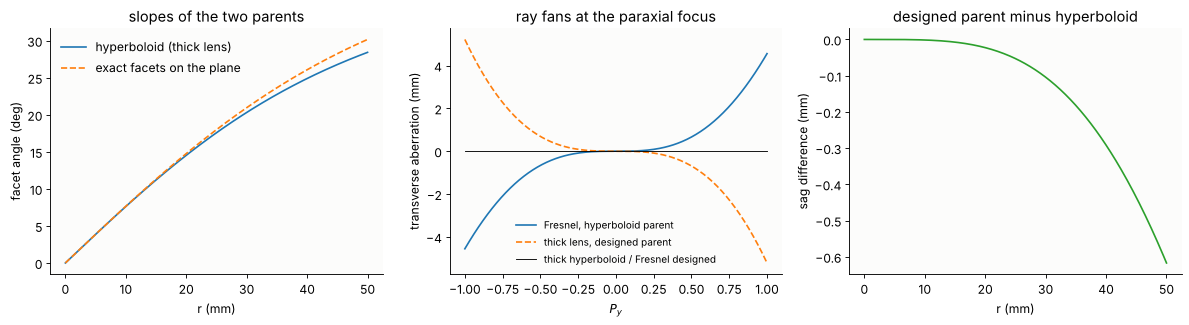

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
rr = np.linspace(0, A, 300)
ax = axes[0]
ax.plot(rr, np.degrees(np.arctan(-hyper._slope_over_r(rr**2)*rr)), label="hyperboloid (thick lens)")
ax.plot(rr, np.degrees(np.arctan(-fr.focusing_slopes(rr, F, N, 1.0))),
        ls="--", label="exact facets on the plane")
ax.set_xlabel("r (mm)"), ax.set_ylabel("facet angle (deg)")
ax.set_title("slopes of the two parents")
ax.legend(frameon=False)
ax = axes[1]
p = np.linspace(-1, 1, 201)
for s, lab, ls in [(ideal_hyp, "Fresnel, hyperboloid parent", "-"),
                   (thick_des, "thick lens, designed parent", "--")]:
    fan = s.ray_fan(0.0, N=201)
    ax.plot(fan.p, fan.ey, ls, label=lab)
ax.plot(p, 0*p, color="k", lw=0.8, label="thick hyperboloid / Fresnel designed")
ax.set_xlabel("$P_y$"), ax.set_ylabel("transverse aberration (mm)")
ax.set_title("ray fans at the paraxial focus")
ax.legend(frameon=False, fontsize=9)
ax = axes[2]
ax.plot(rr, (designed.sag(rr**2) - hyper.sag(rr**2)), color="C2")
ax.set_xlabel("r (mm)"), ax.set_ylabel("sag difference (mm)")
ax.set_title("designed parent minus hyperboloid")
plt.tight_layout()
plt.show()

No. The Fresnel lens with the hyperboloid as parent has ±4.5 mm of
transverse spherical aberration at the rim: the hyperboloid refracts the rim
ray 15 mm closer to the focus than the plane does, so the same slope sends it
to the wrong place. The facets have to be designed for where they actually
sit. `focusing_slopes()` solves the vector law of refraction for the facet
normal, $\mathbf N \parallel n\,\mathbf d - n'\mathbf d'$, at every radius
of the plane, and `surface_from_slopes()` fits an even asphere to those
slopes. This is the **way back** from a Fresnel lens to a thick lens
description: the zone radii plus one smooth parent (here a sphere of
$R = -73.89$ mm with six aspheric terms, slope residual $2\cdot 10^{-7}$) describe
the whole relief. It also works for the facet angle table of a moulded lens.
The parent is a description of the *shape*, not a lens with the same
*function*: used as a solid lens it is now the bad one.

Two conversions are therefore worth keeping apart:

- **same shape** (Fresnel ↔ parent with the same slopes,
  `from_surface()` / `parent_surface()`): what the mould maker needs;
- **same function** (Fresnel ↔ a thick lens with the same ray map): the
  hyperboloid for the exact Fresnel design. The paraxial data agree for both,
  the aberrations do not; `System.seidel()` therefore reports NaN for a
  Fresnel surface.

## 3. Real facets

`model="facets"` traces the real sawtooth: each ray is intersected with the
facets and risers of the zones it can reach, refracted with the normal of
the piece it hits, and its optical path includes the steps. The facets are
on average 0.2 mm away from the base plane, which shifts the rays by
$h\tan\theta'$ (up to 0.1 mm at the rim). Facets that follow the curved
parent are hard to cut; many moulds use **flat (conical) facets**, the chord
of the parent across each zone. A flat facet sends a whole zone in one
direction, so the spot grows with the pitch.

curved facets, RMS spot (um): [  6.6  13.2  31.5  66.1 134.8]
flat facets, RMS spot (um): [ 27.3  53.4 138.4 269.5 532.6]


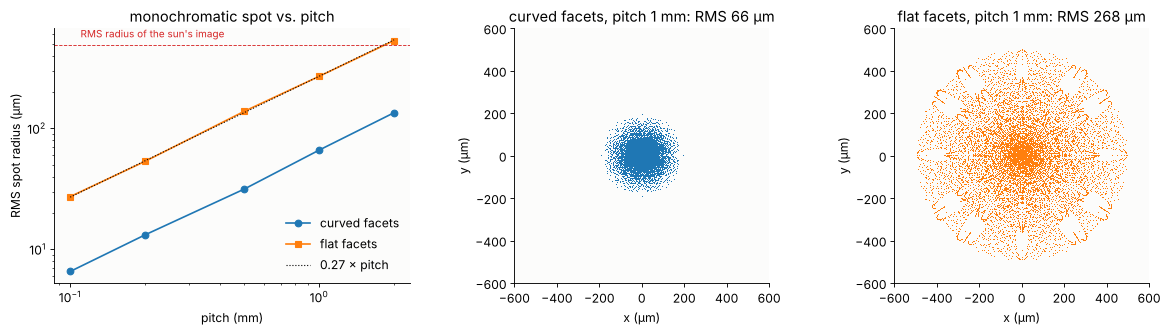

In [6]:
pitches = np.array([0.1, 0.2, 0.5, 1.0, 2.0])
rms = {fac: [concentrator(designed, pitch=p, facets=fac).spot_diagram(0.0, N=81).rms
             for p in pitches] for fac in ("curved", "flat")}
for fac in rms:
    print(fac, "facets, RMS spot (um):", np.round(1e3*np.array(rms[fac]), 1))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), gridspec_kw={"width_ratios": [1.2, 1, 1]})
ax = axes[0]
for fac, m in [("curved", "o-"), ("flat", "s-")]:
    ax.loglog(pitches, 1e3*np.array(rms[fac]), m, label=fac + " facets")
ax.loglog(pitches, 1e3*0.27*pitches, "k:", lw=1, label="0.27 × pitch")
ax.axhline(1e3*F*4.65e-3/np.sqrt(2), color="C3", lw=0.8, ls="--")
ax.text(0.11, 1e3*F*4.65e-3/np.sqrt(2)*1.15, "RMS radius of the sun's image", color="C3", fontsize=9)
ax.set_xlabel("pitch (mm)"), ax.set_ylabel("RMS spot radius (µm)")
ax.set_title("monochromatic spot vs. pitch")
ax.legend(frameon=False)
for ax, fac in zip(axes[1:], ("curved", "flat")):
    sp = concentrator(designed, pitch=1.0, facets=fac).spot_diagram(0.0, N=121)
    ax.plot(1e3*sp.x, 1e3*sp.y, ",", color="C0" if fac == "curved" else "C1")
    ax.set_aspect("equal"), ax.set_xlim(-600, 600), ax.set_ylim(-600, 600)
    ax.set_xlabel("x (µm)"), ax.set_ylabel("y (µm)")
    ax.set_title("{} facets, pitch 1 mm: RMS {:.0f} µm".format(fac, 1e3*sp.rms))
plt.tight_layout()
plt.show()

Both errors grow linearly with the pitch (flat facets: RMS radius about
0.27 times the pitch), and both are small against the sun's image (a disk
of 0.7 mm radius at $f = 150$ mm, dashed line: its RMS radius): for a
concentrator a 0.5 mm pitch with flat facets is perfectly adequate. For an
imaging Fresnel lens (a camera field lens, a VR eyepiece) the facet height
error would be designed out, or the pitch made much finer.

## 4. Where the light goes: risers, shadows and reflections

A ray can fail at a Fresnel surface in three ways that a smooth lens does not
have (`FresnelSurface.classify()`, `fresnel.facet_losses()`):

- **riser** – it hits a riser first. With a draft angle the risers cover a
  ring of width $|h_k|\tan\delta$ at the start of every zone;
- **shadowed** – after the facet it hits the relief again, the next riser,
  before it has left the grooves;
- **TIR** – total internal reflection at a too steep facet.

In the trace these rays are lost (`stray="refract"` follows riser hits on
as stray light). The orientation of the relief matters. With the grooves
facing the cell (exit side), collimated light inside the glass runs
parallel to the risers and leaves through the facets inwards, away from the
next riser. With the grooves facing the sun (entrance side), the light is refracted inwards
*inside* the glass and runs into the wall of the neighbouring zone. Both
lenses below are designed exactly for their orientation; for the entrance
side, the facets must send the rays into directions that the flat exit face
then refracts to the focus (`focusing_slopes(..., d_out=...)`).

In [7]:
# entrance-side design: in-glass directions that the flat exit (3 mm further) bends to the focus
th_a = np.arctan(r_d/F)
for _ in range(60):
    th_g = np.arcsin(np.sin(th_a)/N)
    th_a = np.arctan((r_d - T*np.tan(th_g))/F)
d_glass = np.stack([0*r_d, -np.sin(th_g), np.cos(th_g)], -1)
designed_in, _ = fr.surface_from_slopes(r_d, fr.focusing_slopes(r_d, None, 1.0, N, d_out=d_glass),
                                        n_aspheric=6)

lens_out = concentrator(designed, draft=DRAFT)
fs_in = FresnelSurface.from_surface(designed_in, thickness=T, material=fr.pmma, semi_diameter=A,
                                    pitch=PITCH, draft=DRAFT)
lens_in = System([fs_in, Surface(np.inf, F, n_after=1.0, semi_diameter=A)], 0, WL,
                 ray_aiming=False)   # the stop is on the relief, collimated light: no aiming

px, py = fr.vogel_spiral(40000)
res = {}
for name, s, i in [("grooves to the cell", lens_out, 1), ("grooves to the sun", lens_in, 0)]:
    L = fr.facet_losses(s, i, px=px, py=py)
    Tf = s.trace_pupil_polarization(0.0, px, py).transmittance()   # unpolarized, both faces
    res[name] = (L, np.nan_to_num(Tf))
    print("{:20s} facet {:.1%}, riser {:.1%}, shadowed {:.1%}, TIR {:.1%};  with the Fresnel "
          "reflections: {:.1%} reaches the focus".format(name, L.fractions["facet"],
          L.fractions["riser"], L.fractions["shadowed"], L.fractions["TIR"],
          np.mean(np.nan_to_num(Tf))))

grooves to the cell  facet 98.6%, riser 1.4%, shadowed 0.0%, TIR 0.0%;  with the Fresnel reflections: 90.6% reaches the focus


grooves to the sun   facet 93.5%, riser 1.5%, shadowed 5.0%, TIR 0.0%;  with the Fresnel reflections: 86.2% reaches the focus


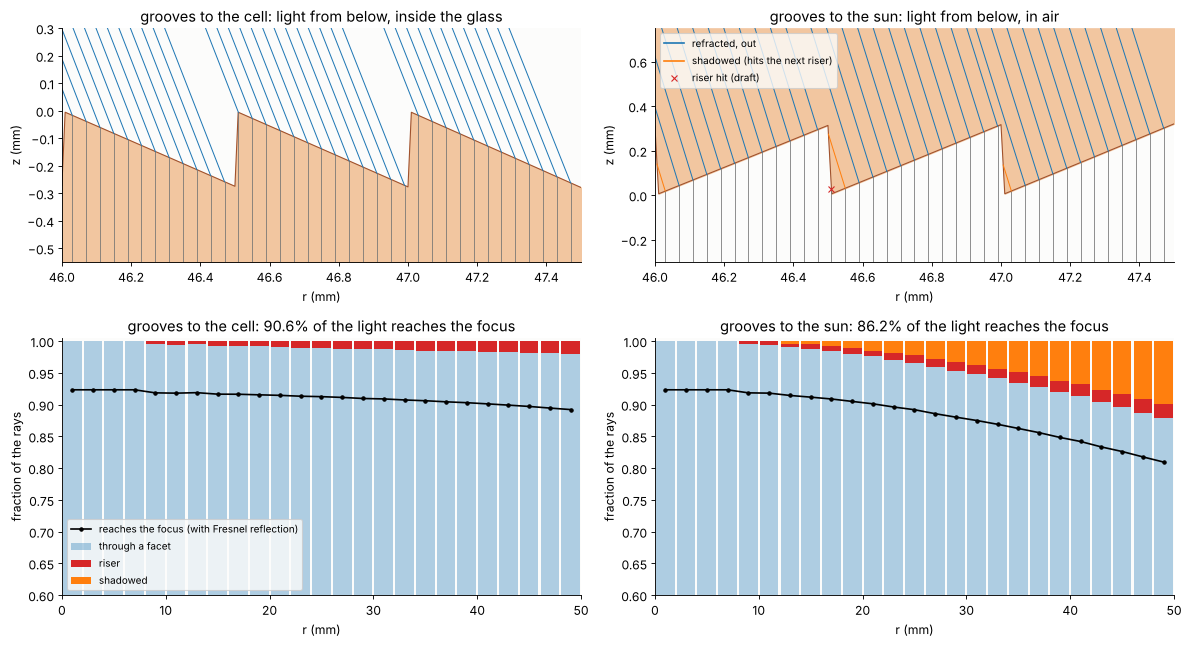

In [8]:
def ray_sketch(ax, s, i, rays_r, window, zlim, glass_below):
    # a few zones near the rim in the local frame of the Fresnel surface: rays to their
    # first hit, refracted, and on to a second hit (shadowed) or out of the grooves
    fs = s.surfaces[i]
    o, Rm = s.frames()[0][i]
    rr = np.linspace(*window, 4000)
    zz = fs.profile(rr)
    ax.fill_between(rr, zz, zlim[0] if glass_below else zlim[1], color="#f2c6a0")
    ax.plot(rr, zz, color="#a0522d", lw=1)
    pyr = rays_r/A
    rays = s.rays(0.0, 0*pyr, pyr)
    b = s.trace(rays, clip=False, last=i - 1) if i > 0 else None
    P = (b.points[-1] if b is not None else np.asarray(rays.points)) - o
    d = b.directions[-1] if b is not None else np.asarray(rays.directions)
    P, d = P @ Rm, d @ Rm
    n1, n2 = s.n[i], s.n[i + 1]
    code, Q = fs.classify(P, d, n1, n2)
    d2 = fs._refract(fs.normal(Q), d, n1, n2)
    t2, piece = fs._first_hit(Q, d2, t_min=np.full(len(Q), 1e-7*A))
    colors = {FACET: "C0", RISER: "C3", SHADOWED: "C1"}
    for j in range(len(Q)):
        start = Q[j] - d[j]*(abs(Q[j, 2] - (zlim[0] if d[j, 2] > 0 else zlim[1]))/abs(d[j, 2]))
        ax.plot([start[1], Q[j, 1]], [start[2], Q[j, 2]], color="0.45", lw=0.7)
        if code[j] == RISER:
            ax.plot(Q[j, 1], Q[j, 2], "x", color="C3", ms=6)
            continue
        end = Q[j] + d2[j]*(t2[j] if np.isfinite(t2[j]) else 1.0)
        ax.plot([Q[j, 1], end[1]], [Q[j, 2], end[2]], color=colors.get(code[j], "k"), lw=0.9)
    ax.set_xlim(*window), ax.set_ylim(*zlim)
    ax.set_xlabel("r (mm)"), ax.set_ylabel("z (mm)")


fig, axes = plt.subplots(2, 2, figsize=(15, 8.2), gridspec_kw={"height_ratios": [1, 1.1]})
ray_sketch(axes[0, 0], lens_out, 1, np.linspace(46.03, 47.47, 37), (46.0, 47.5), (-0.55, 0.3), True)
axes[0, 0].set_title("grooves to the cell: light from below, inside the glass")
ray_sketch(axes[0, 1], lens_in, 0, np.linspace(46.03, 47.47, 37), (46.0, 47.5), (-0.3, 0.75), False)
axes[0, 1].set_title("grooves to the sun: light from below, in air")
for ax in axes[0]:
    ax.plot([], [], color="C0", label="refracted, out")
    ax.plot([], [], color="C1", label="shadowed (hits the next riser)")
    ax.plot([], [], "x", color="C3", label="riser hit (draft)")
axes[0, 1].legend(loc="upper left", fontsize=9, frameon=True)

edges = np.linspace(0, A, 26)
mid = 0.5*(edges[1:] + edges[:-1])
for ax, (name, (L, Tf)) in zip(axes[1], res.items()):
    k = np.digitize(L.r, edges) - 1
    frac = {c: np.array([np.mean(L.code[k == j] == c) for j in range(len(mid))])
            for c in (FACET, RISER, SHADOWED)}
    T_bin = np.array([np.mean(Tf[k == j]) for j in range(len(mid))])
    w = edges[1] - edges[0]
    ax.bar(mid, frac[FACET], w*0.9, color="C0", alpha=0.35, label="through a facet")
    ax.bar(mid, frac[RISER], w*0.9, bottom=frac[FACET], color="C3", label="riser")
    ax.bar(mid, frac[SHADOWED], w*0.9, bottom=frac[FACET] + frac[RISER], color="C1",
           label="shadowed")
    ax.plot(mid, T_bin, "k.-", label="reaches the focus (with Fresnel reflection)")
    ax.set_ylim(0.6, 1.005), ax.set_xlim(0, A)
    ax.set_xlabel("r (mm)"), ax.set_ylabel("fraction of the rays")
    ax.set_title("{}: {:.1%} of the light reaches the focus".format(name, Tf.mean()))
axes[1, 0].legend(loc="lower left", fontsize=9, frameon=True)
plt.tight_layout()
plt.show()

With the grooves towards the cell, only the draft costs light (1.4 %, most
at the rim where the grooves are deepest), and the two faces reflect 8 %
(more at the rim, where the exit angle at the facets reaches 40°). With the
grooves towards the sun, the refracted rays inside the glass run into the
next riser: 5 % of the light, at the rim up to a third of a zone, is
shadowed. That, and dirt in the grooves, is why CPV lenses are mounted with
the smooth side up. On top of this, real lenses lose light at the rounded
tips and valleys of the moulded grooves, which this model does not have.

## 5. The sun in colour

The sun is not a point: its disk has a radius of 4.65 mrad (0.27°), and
the cell sees its light from 400 nm to beyond 1600 nm. PMMA disperses by
0.027 between 400 and 1100 nm, which moves the focus by
$f\,\Delta n/(n-1) \approx 8$ mm. Below, the sun is traced as 20 000 rays
per wavelength with random directions in its disk and random points on the
lens, over 15 wavelengths weighted with a 5778 K black body (a stand-in for
the direct solar spectrum; the PMMA formula is extrapolated a little
outside 437 to 1052 nm). `System.trace()` takes rays with individual
directions, so one trace per wavelength does it.

In [9]:
lams = np.linspace(400, 1100, 15)
h_P, c0, kB = 6.626e-34, 2.998e8, 1.381e-23
planck = lambda l: 1/(l*1e-9)**5/(np.exp(h_P*c0/(l*1e-9*kB*5778)) - 1)
weights = planck(lams)/planck(lams).sum()
SUN = 4.65e-3                      # angular radius of the sun (rad)
rng = np.random.default_rng(7)


def sun_rays(n_rays, tilt=0.0):
    # random points on the lens, random directions in the solar disk (tilted by the tracking error)
    rho, phi = A*np.sqrt(rng.random(n_rays)), 2*np.pi*rng.random(n_rays)
    a, b = SUN*np.sqrt(rng.random(n_rays)), 2*np.pi*rng.random(n_rays)
    d = np.stack([np.tan(a*np.cos(b)), np.tan(a*np.sin(b) + tilt), np.ones(n_rays)], -1)
    d /= np.linalg.norm(d, axis=1)[:, None]
    P = np.stack([rho*np.cos(phi), rho*np.sin(phi), np.full(n_rays, -1.0)], -1)
    return Rays(P, d, np.zeros(n_rays))


def on_receiver(system, z, tilt=0.0, n_rays=20000, wavelengths=lams, w=weights):
    # hits (x, y) and power weights of all wavelengths in the plane z
    X, W = [], []
    for lam, wt in zip(wavelengths, w):
        b = system.with_wavelength(lam*1e-6).trace(sun_rays(n_rays, tilt))
        P, d = b.points[-1][b.valid], b.directions[-1][b.valid]
        X.append(P[:, :2] + ((z - P[:, 2])/d[:, 2])[:, None]*d[:, :2])
        W.append(np.full(len(P), wt/n_rays))
    return np.concatenate(X), np.concatenate(W)


HALF = 2.5                          # half side of the cell (mm)
z_focus = lens_out.image_z
shifts = np.linspace(-4, 3, 8)
on_cell = []
for dz in shifts:
    X, W = on_receiver(lens_out, z_focus + dz, n_rays=4000)
    on_cell.append(W[np.all(np.abs(X) <= HALF, axis=1)].sum())
dz_best = shifts[np.argmax(on_cell)]
print("power on the cell vs. receiver position:", np.round(on_cell, 3), "-> best at", dz_best,
      "mm from the 550 nm focus")
Z_CELL = z_focus + dz_best
X, W = on_receiver(lens_out, Z_CELL)
X1, W1 = on_receiver(lens_out, z_focus, wavelengths=[550.0], w=[1.0])
geo = np.pi*A**2/(2*HALF)**2
eff = W[np.all(np.abs(X) <= HALF, axis=1)].sum()
print("geometric concentration {:.0f} suns; on the cell {:.1%} of the light that leaves the lens "
      "-> {:.0f} suns before reflection losses".format(geo, eff, geo*eff))

power on the cell vs. receiver position: [0.963 0.977 0.984 0.985 0.985 0.982 0.978 0.969] -> best at -1.0 mm from the 550 nm focus


geometric concentration 314 suns; on the cell 98.6% of the light that leaves the lens -> 310 suns before reflection losses


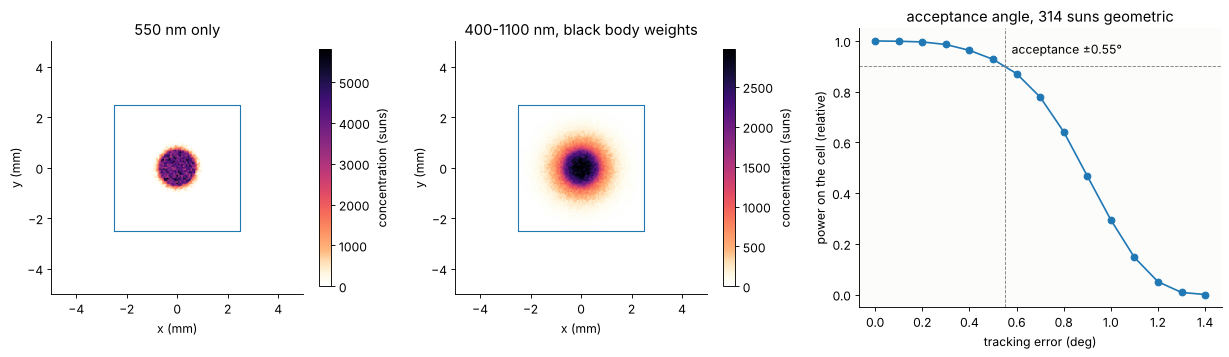

90 % acceptance half angle: 0.55 deg


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.6), gridspec_kw={"width_ratios": [1, 1, 1.15]})
ext = 5.0
for ax, (XX, WW, title) in zip(axes[:2], [(X1, W1, "550 nm only"),
                                          (X, W, "400-1100 nm, black body weights")]):
    H, xe, ye = np.histogram2d(XX[:, 0], XX[:, 1], bins=161, range=[[-ext, ext]]*2, weights=WW)
    conc = H/(xe[1] - xe[0])**2*np.pi*A**2        # local concentration (suns, lossless)
    im = ax.imshow(conc.T, extent=[-ext, ext, -ext, ext], origin="lower", cmap=LIGHT,
                   vmax=np.percentile(conc[conc > 0], 99.5))
    ax.plot([-HALF, HALF, HALF, -HALF, -HALF], [-HALF, -HALF, HALF, HALF, -HALF], color="C0", lw=1)
    ax.set_xlabel("x (mm)"), ax.set_ylabel("y (mm)"), ax.set_title(title)
    plt.colorbar(im, ax=ax, label="concentration (suns)", shrink=0.85)

# acceptance: power on the cell vs. tracking error
tilts = np.radians(np.linspace(0, 1.4, 15))
acc = []
for tl in tilts:
    XX, WW = on_receiver(lens_out, Z_CELL, tilt=tl, n_rays=3000)
    acc.append(WW[np.all(np.abs(XX) <= HALF, axis=1)].sum())
acc = np.array(acc)
a90 = np.degrees(np.interp(0.9*acc[0], acc[::-1], tilts[::-1]))
ax = axes[2]
ax.plot(np.degrees(tilts), acc/acc[0], "o-")
ax.axhline(0.9, color="0.5", lw=0.8, ls="--")
ax.axvline(a90, color="0.5", lw=0.8, ls="--")
ax.text(a90 + 0.03, 0.95, "acceptance ±{:.2f}°".format(a90))
ax.set_xlabel("tracking error (deg)"), ax.set_ylabel("power on the cell (relative)")
ax.set_title("acceptance angle, {:.0f} suns geometric".format(geo))
plt.tight_layout()
plt.show()
print("90 % acceptance half angle: {:.2f} deg".format(a90))

At one wavelength the cell would see a sharp disk, the image of the sun
($2f\cdot 4.65$ mrad = 1.4 mm across). In white light the axial colour of PMMA dominates: the
blue focus lies in front, the infrared one behind the cell, and their out of
focus disks make the broad halo, so the receiver sits about a millimetre in
front of the 550 nm focus where the polychromatic spot is smallest. The cell
still collects 98.6 % of the light that leaves the lens, about 310 suns,
but a tracking error of more than half a degree pushes the spot off the cell; that acceptance
angle is what secondary optics (a glass prism or dome on the cell) of real
CPV modules widen.

## 6. Waves: Fresnel lens vs. kinoform

The steps of the CPV lens are up to 240 waves of optical path deep
($(n - 1)h/\lambda$ at the rim), and they are not whole numbers of waves. Behind the lens, every zone is a ring that focuses its light into the
geometric focus, but with an arbitrary phase: the zones add up
**incoherently**. A **kinoform** is a Fresnel lens with the groove depth
$\lambda_0/(n - 1)$ (`zone_radii(..., depth=...)`, `kinoform_depth()`):
every step is exactly one wave at $\lambda_0$, the zones add up in phase,
and the zone radii are those of a zone plate, $r_k^2 \approx 2k\lambda_0 f$.
It is a diffractive lens: at another wavelength the step is
$\alpha = \lambda_0(n(\lambda) - 1)/(\lambda(n_0 - 1))$ waves, the order
$m$ gets the scalar efficiency $\mathrm{sinc}^2(\alpha - m)$ and focuses at
$f\,m\lambda_0/\lambda$ (`kinoform_efficiency()`), a dispersion with the
Abbe number $-3.45$ instead of $+57$ for PMMA.

Rays cannot see any of this: through the 1 µm deep kinoform facets, the
rays still refract like those of the deep Fresnel lens. Here the thin
element approximation does the waves: the relief `FresnelSurface.profile()`
gives the transmission $\exp(i k_0 (n - 1) z(r))$, and the field near the
focus is the Fresnel integral of a rotationally symmetric field,

$$U(\rho, z) = \frac{k}{i z}\, e^{ikz + ik\rho^2/2z}\int_0^a U_0(r)\,
e^{ikr^2/2z} J_0\!\left(\frac{k\rho r}{z}\right) r\,\mathrm dr .$$

A small lens keeps it cheap: radius 2 mm, $f = 20$ mm (NA 0.1), a parabolic
parent (exact quadratic phase in the thin element limit), 0.1 mm pitch
for the refractive Fresnel lens (20 zones, steps of up to 18 waves), and
182 zones for the kinoform.

deep Fresnel lens: 20 zones, steps of 0 to 18 waves; kinoform: 182 zones, first zone radius 0.148 mm (sqrt(2 lambda f) = 0.148)


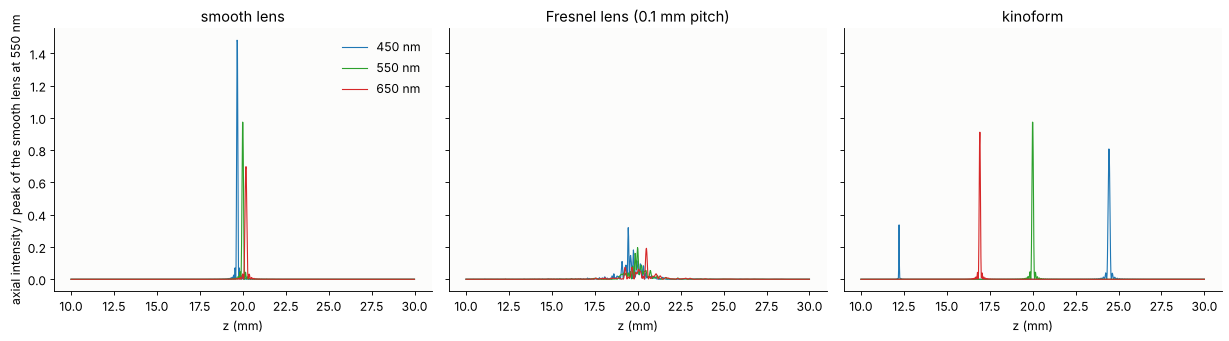

In [11]:
a_w, f_w = 2.0, 20.0
lam0 = 550e-6
parab = Surface(-(N - 1)*f_w, conic=-1.0)
smooth = lambda r: parab.sag(r**2)
deep = FresnelSurface.from_surface(parab, pitch=0.1, radius=a_w)
kino = FresnelSurface.from_surface(parab, depth=fr.kinoform_depth(lam0, N), radius=a_w)
print("deep Fresnel lens: {} zones, steps of {:.0f} to {:.0f} waves; kinoform: {} zones, first zone "
      "radius {:.3f} mm (sqrt(2 lambda f) = {:.3f})".format(
          deep.n_zones, (N - 1)*abs(deep._geometry()["h"][0])/lam0,
          (N - 1)*abs(deep._geometry()["h"][-1])/lam0, kino.n_zones, kino.zones[1],
          np.sqrt(2*lam0*f_w)))

r_w = (np.arange(60000) + 0.5)*a_w/60000
dr = r_w[1] - r_w[0]
profiles = {"smooth lens": smooth(r_w), "Fresnel lens (0.1 mm pitch)": deep.profile(r_w),
            "kinoform": kino.profile(r_w)}


def axial(height, lam, z):
    k = 2*np.pi/lam
    U0 = np.exp(1j*k*(fr.pmma(lam*1e6) - 1)*height)
    E = np.exp(1j*k*r_w[None, :]**2/(2*z[:, None]))
    return np.abs(k/z*(E @ (U0*r_w))*dr)**2


def radial(height, lam, z, rho):
    k = 2*np.pi/lam
    U0 = np.exp(1j*k*(fr.pmma(lam*1e6) - 1)*height)*np.exp(1j*k*r_w**2/(2*z))*r_w
    return np.abs(k/z*(j0(k*rho[:, None]*r_w[None, :]/z) @ U0)*dr)**2


z_ax = np.linspace(10, 30, 1000)
I0 = axial(profiles["smooth lens"], lam0, np.array([f_w]))[0]    # peak of the smooth lens
colors = {450: "C0", 550: "C2", 650: "C3"}
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4), sharey=True)
for ax, (name, hgt) in zip(axes, profiles.items()):
    for lam_nm, col in colors.items():
        ax.plot(z_ax, axial(hgt, lam_nm*1e-6, z_ax)/I0, color=col, lw=1, label="{} nm".format(lam_nm))
    ax.set_title(name), ax.set_xlabel("z (mm)")
axes[0].set_ylabel("axial intensity / peak of the smooth lens at 550 nm")
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

The smooth lens and the deep Fresnel lens focus all colours near 20 mm
(PMMA: 0.5 mm from 450 to 650 nm). But the Fresnel lens reaches only a
fraction of the peak intensity, a different fraction at every wavelength:
its 20 rings interfere with phases that the step depths set. The kinoform
at 550 nm is as good as the smooth lens; at 450 nm its focus moves *out*
to 24 mm and at 650 nm *in* to 17 mm ($f\lambda_0/\lambda$), the reverse of
glass and 15 times stronger, with weaker peaks: the light missing there goes
into the other orders.

incoherent zone sum: Strehl 0.067; mean over 540-560 nm 0.083


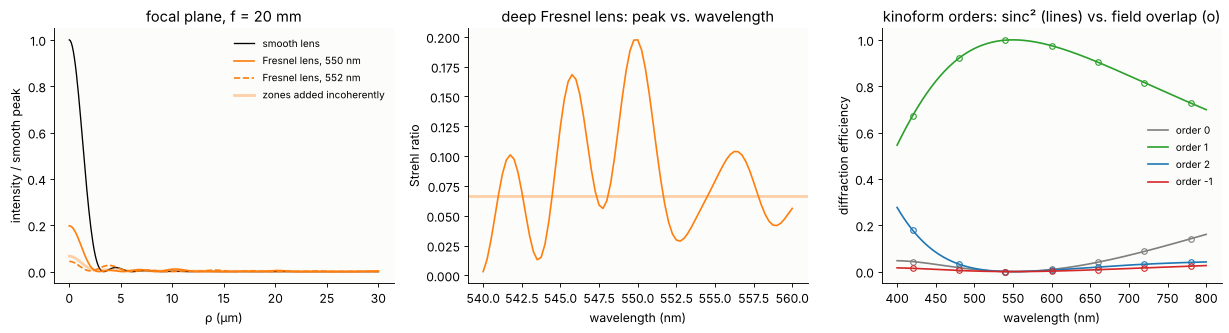

In [12]:
rho = np.linspace(0, 0.03, 301)
lam_scan = np.linspace(540, 560, 81)*1e-6
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.3))
ax = axes[0]
I_s = radial(profiles["smooth lens"], lam0, f_w, rho)
ax.plot(1e3*rho, I_s/I_s[0], color="k", lw=1.2, label="smooth lens")
for lam_nm, ls in [(550.0, "-"), (552.0, "--")]:
    I_d = radial(profiles["Fresnel lens (0.1 mm pitch)"], lam_nm*1e-6, f_w, rho)
    ax.plot(1e3*rho, I_d/I_s[0], ls, color="C1", label="Fresnel lens, {:.0f} nm".format(lam_nm))
# incoherent sum of the zones: the zones' focal fields added in intensity
zone = np.clip(np.searchsorted(deep.zones, r_w, side="right") - 1, 0, deep.n_zones - 1)
I_inc = 0
for kz in range(deep.n_zones):
    sel = np.where(zone == kz, 1.0, 0.0)
    k = 2*np.pi/lam0
    U0 = sel*np.exp(1j*k*r_w**2/(2*f_w) + 1j*k*(N - 1)*profiles["Fresnel lens (0.1 mm pitch)"])*r_w
    I_inc = I_inc + np.abs(k/f_w*(j0(k*rho[:, None]*r_w[None, :]/f_w) @ U0)*dr)**2
ax.plot(1e3*rho, I_inc/I_s[0], color="C1", lw=2.5, alpha=0.35, label="zones added incoherently")
ax.set_xlabel("ρ (µm)"), ax.set_ylabel("intensity / smooth peak")
ax.set_title("focal plane, f = 20 mm")
ax.legend(frameon=False, fontsize=9)

ax = axes[1]
strehl = [radial(profiles["Fresnel lens (0.1 mm pitch)"], lam, f_w, np.zeros(1))[0]
          / radial(profiles["smooth lens"], lam, f_w, np.zeros(1))[0] for lam in lam_scan]
ax.plot(lam_scan*1e6, strehl, color="C1")
ax.axhline(I_inc[0]/I_s[0], color="C1", lw=2.5, alpha=0.35)
ax.set_xlabel("wavelength (nm)"), ax.set_ylabel("Strehl ratio")
ax.set_title("deep Fresnel lens: peak vs. wavelength")
print("incoherent zone sum: Strehl {:.3f}; mean over 540-560 nm {:.3f}".format(
    I_inc[0]/I_s[0], np.mean(strehl)))

ax = axes[2]
lam_e = np.linspace(400, 800, 201)*1e-6
k_r2 = 2*np.pi*r_w**2/(2*f_w)
for m, col in [(0, "C7"), (1, "C2"), (2, "C0"), (-1, "C3")]:
    eta = fr.kinoform_efficiency(m, lam_e, lam0, fr.pmma(lam_e*1e6), N)
    ax.plot(lam_e*1e6, eta, color=col, label="order {}".format(m))
    # numerical: overlap of the kinoform field with an ideal lens of order m (f lambda0 / (m lambda))
    lam_pts = np.linspace(420, 780, 7)*1e-6
    num = []
    for lam in lam_pts:
        U = np.exp(1j*2*np.pi/lam*(fr.pmma(lam*1e6) - 1)*profiles["kinoform"])
        ref = np.exp(-1j*m*k_r2/lam0)
        num.append(np.abs(np.sum(U*np.conj(ref)*r_w)/np.sum(r_w))**2)
    ax.plot(lam_pts*1e6, num, "o", color=col, ms=5, mfc="none")
ax.set_xlabel("wavelength (nm)"), ax.set_ylabel("diffraction efficiency")
ax.set_title("kinoform orders: sinc² (lines) vs. field overlap (o)")
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

Two nanometres of wavelength change the focus of the deep Fresnel lens
completely: its Strehl ratio jumps between almost 0 and 0.2 as the step
phases go through their cycles. Averaged over even a narrow band it is the
**incoherent sum of the zones** (thick line). Each thin ring alone focuses
into a $J_0^2$ pattern with a narrow core and its power spread over the
diffraction angle of the zone width ($\lambda/p = 5.5$ mrad, about 110 µm at
20 mm); added in intensity, the zones $k$ of area $\propto 2k + 1$ give the
Strehl ratio $\sum_k (2k+1)^2/(\sum_k (2k+1))^2 = (4K^2 - 1)/(3K^3) = 0.067$
for $K = 20$ zones, as computed. The peak of the rays' focus is gone; their
power stays near it. This is why a ray trace with the facets model, with
diffraction at the zones as an afterthought, describes a solar concentrator
or a projector condenser perfectly well, and why nobody images with deep
Fresnel lenses. The kinoform is the other limit: coherent and diffraction
limited, but only near its design wavelength. The efficiency of its orders
from the overlap of the thin element field with ideal lenses of focal length
$f\lambda_0/(m\lambda)$ (circles) agrees with the scalar formula. Hybrid
refractive-diffractive lenses use exactly this: a weak kinoform with its
Abbe number of $-3.45$ corrects the colour of a glass lens.

## Summary

- `FresnelSurface.from_surface()` collapses a thick lens surface (sphere,
  conic, asphere) into zones of constant pitch or constant depth, with curved
  or flat facets and drafted risers; `parent_surface()` and
  `surface_from_slopes()` go back to a smooth parent.
- Same slopes are not the same lens: the Fresnel version of the aberration
  free hyperboloid has millimetres of spherical aberration at F/1.5. Design
  the facets on their plane (`focusing_slopes()`), then fit the parent.
- `model="ideal"` (rays on the plane, parent normals) is the limit of a fine
  relief; `model="facets"` traces the sawtooth, with the groove depth, flat
  facet blur ≈ pitch, and the losses at risers (draft), by shadowing and by
  TIR (`facet_losses()`), plus the Fresnel reflections of
  `trace_polarization()`.
- The CPV lens: grooves towards the cell, 98.6 % of the rays pass the relief
  and about 90 % reach the cell with the reflections; grooves towards the
  sun lose another 5 % to shadowing. Colour, not the facets, sets the size of
  the solar spot and with it the concentration and acceptance angle.
- Waves: deep zones add incoherently (the rays' focus, blurred by the zone
  width), one wave deep zones make a kinoform, a diffractive lens with
  $V = -3.45$ and sinc² efficiencies.

In [13]:
print("run time {:.0f} s".format(time.time() - t_start))

run time 93 s
